In [106]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv


In [107]:
import pandas as pd
import numpy as np

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score

import warnings
warnings.filterwarnings("ignore")

In [108]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv


In [109]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv")

df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [110]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [111]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [112]:
df.isnull().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [113]:
print(df.columns)

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')


In [114]:
df.shape

(569, 33)

In [115]:
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

In [116]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y)

In [117]:
print(df.columns)

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')


In [118]:
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

In [119]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y)

In [120]:
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

In [121]:
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

In [122]:
print(df.columns.tolist())

['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


In [123]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y)

In [124]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [125]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [126]:
from sklearn.linear_model import LogisticRegression

baseline = LogisticRegression(max_iter=1000)

baseline.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [127]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    baseline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Baseline CV Accuracy:", cv_scores.mean())

Baseline CV Accuracy: 0.9714285714285715


In [128]:
from sklearn.metrics import accuracy_score

baseline_pred = baseline.predict(X_test)

baseline_test_acc = accuracy_score(y_test, baseline_pred)

print("Baseline Test Accuracy:", baseline_test_acc)

Baseline Test Accuracy: 0.9649122807017544


In [129]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear", "lbfgs"]
}

grid = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", grid.best_score_)

Best Parameters: {'C': 0.1, 'solver': 'liblinear'}
Best CV Accuracy: 0.9736263736263737


In [130]:
grid_pred = grid.predict(X_test)

grid_test_acc = accuracy_score(y_test, grid_pred)

print("GridSearch Test Accuracy:", grid_test_acc)

GridSearch Test Accuracy: 0.9824561403508771


In [131]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear", "lbfgs"]
}

random = RandomizedSearchCV(
    LogisticRegression(max_iter=1000),
    param_distributions=param_dist,
    n_iter=6,
    cv=5,
    scoring="accuracy",
    random_state=42
)

random.fit(X_train, y_train)

print("Best Parameters:", random.best_params_)
print("Best CV Accuracy:", random.best_score_)

Best Parameters: {'solver': 'liblinear', 'C': 0.1}
Best CV Accuracy: 0.9736263736263737


In [132]:
random_pred = random.predict(X_test)

random_test_acc = accuracy_score(y_test, random_pred)

print("RandomizedSearch Test Accuracy:", random_test_acc)

RandomizedSearch Test Accuracy: 0.9824561403508771


In [133]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [134]:
rf_cv = cross_val_score(
    rf,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

rf_pred = rf.predict(X_test)

rf_test_acc = accuracy_score(y_test, rf_pred)

print("Random Forest CV Accuracy:", rf_cv.mean())
print("Random Forest Test Accuracy:", rf_test_acc)

Random Forest CV Accuracy: 0.9560439560439562
Random Forest Test Accuracy: 0.956140350877193


In [135]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "GridSearchCV",
        "RandomizedSearchCV",
        "Random Forest"
    ],
    "CV Accuracy": [
        cv_scores.mean(),
        grid.best_score_,
        random.best_score_,
        rf_cv.mean()
    ],
    "Test Accuracy": [
        baseline_test_acc,
        grid_test_acc,
        random_test_acc,
        rf_test_acc
    ],
    "Best Params": [
        "Default",
        grid.best_params_,
        random.best_params_,
        "Default"
    ]
})

results

,Model,CV Accuracy,Test Accuracy,Best Params
0,Baseline Logistic Regression,0.971429,0.964912,Default
1,GridSearchCV,0.973626,0.982456,"{'C': 0.1, 'solver': 'liblinear'}"
2,RandomizedSearchCV,0.973626,0.982456,"{'solver': 'liblinear', 'C': 0.1}"
3,Random Forest,0.956044,0.956140,Default


In [136]:
from sklearn.metrics import classification_report

best_pred = grid.predict(X_test)

print(classification_report(y_test, best_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.99        72
           1       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [137]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, best_pred)

print(cm)

[[72  0]
 [ 2 40]]


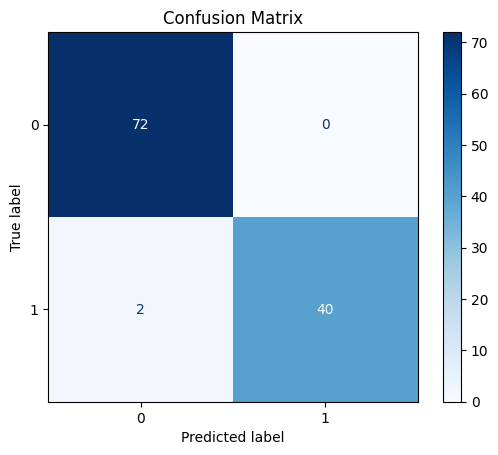

In [138]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(
    grid,
    X_test,
    y_test,
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.show()

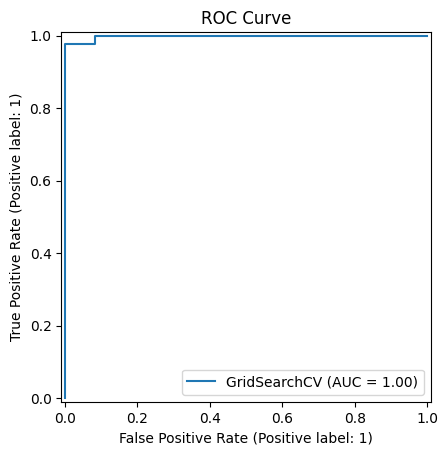

In [139]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(
    grid,
    X_test,
    y_test
)

plt.title("ROC Curve")
plt.show()

In [140]:
from sklearn.metrics import roc_auc_score

prob = grid.predict_proba(X_test)[:,1]

auc = roc_auc_score(y_test, prob)

print("AUC Score:", auc)

AUC Score: 0.998015873015873


In [141]:
import pandas as pd

importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": grid.best_estimator_.coef_[0]
})

importance["Absolute"] = importance["Coefficient"].abs()

importance = importance.sort_values(
    by="Absolute",
    ascending=False
)

importance.head(10)

,Feature,Coefficient,Absolute
22,texture_worst,0.593089,0.593089
21,radius_worst,0.510171,0.510171
11,radius_se,0.488268,0.488268
24,area_worst,0.487941,0.487941
23,perimeter_worst,0.467309,0.467309
8,concave points_mean,0.454391,0.454391
29,symmetry_worst,0.446403,0.446403
28,concave points_worst,0.426157,0.426157
2,texture_mean,0.415001,0.415001
14,area_se,0.393829,0.393829


In [142]:
import joblib

joblib.dump(grid.best_estimator_, "breast_cancer_best_model.pkl")

print("Model saved successfully.")

Model saved successfully.


# Breast Cancer Diagnosis using Machine Learning

## 1. Import Libraries

## 2. Load Dataset

## 3. Data Preprocessing

## 4. Exploratory Data Analysis

## 5. Feature Selection

## 6. Train-Test Split

## 7. Baseline Logistic Regression

## 8. Hyperparameter Tuning using GridSearchCV

## 9. Hyperparameter Tuning using RandomizedSearchCV

## 10. Random Forest Model

## 11. Model Comparison

## 12. Evaluation Metrics

## 13. Feature Importance

## 14. Save Best Model

## 15. Conclusion

# Conclusion

This project predicts whether a breast tumor is malignant or benign using machine learning.

Four models were evaluated:
- Baseline Logistic Regression
- GridSearchCV
- RandomizedSearchCV
- Random Forest

The tuned Logistic Regression model achieved the highest performance.

Best Model:
- Logistic Regression (GridSearchCV)

Best Parameters:
- C = 0.1
- Solver = liblinear

Performance:
- Cross Validation Accuracy: 97.36%
- Test Accuracy: 98.25%

The trained model was successfully saved using Joblib for future predictions.